In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [13]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi

In [14]:
prefix = '/mnt/staging/' # or '/scratch/' for s1n3/4
analysis_root = str(STEPS) + "/"
dlc_path = analysis_root+'DLC_h5s/'
step_1_root = analysis_root+'step_1/'
step_2_root = analysis_root+'step_2/'
step_3_root = analysis_root+'step_3/'
step_0_root = analysis_root+'step_0/'
mouse='cm241'



# licking indices

In [15]:
time_dict = {'cm241_8_runB':[
    [26341,26670],],
'cm241_8_runH':[
[20786,20922],],
'cm241_8_runI':[
[7815 , 8040],
[8129,8140],
[8261,8285],
[8597, 8625],
[8866,8892],
[9455 , 9485],
[22935, 23010],
[23135,23230],
[23346,23380],
[23511, 23522],
[23611, 23640],
[23839,23880],
[24264, 24280],
[24390, 24460],
[25830, 25860],
[29958,30031],
[31168 , 31206],
[31340, 31370],
[31688,31718],
[31864, 31883],],
'cm241_8_runJ':[
[3706 ,3720],
[4440 , 4470],
[4507,4530],
[4600,4630],
[4741,4780],
[14510 , 14570],
[14637,14667],
[33586,33610],
[33936,34000],
[34053,34081],
[34125, 34180],],
'cm241_8_runK':[
[3265,3280],
[3302,3325],
[3423,3467],
[3516,3575],
[3835,3880],
[33632,33900]],
# 'cm241_9_runB':[
# [18480, 18493],
# [28408, 28415]],
# 'cm241_10_runC':[
# [26603,26630],
# [27127,27160],
# [28285,28292]],
# 'cm241_10_runD':[
# [13000,13020],
# [21313, 21320]]
            }


In [21]:
# start_stop_ind=pd.DataFrame(time_dict['cm229_9_runJ'])
# start_stop_ind=start_stop_ind/4-500
# start_stop_ind=start_stop_ind.round().astype('int')
# start_stop_ind['duration'] = start_stop_ind[1]-start_stop_ind[0]
# start_stop_ind['distance_difference'] = start_stop_ind[0] - start_stop_ind[1].shift(1)
# start_stop_ind = start_stop_ind.fillna(10000)
# start_stop_ind = start_stop_ind[start_stop_ind[0]>0]

In [16]:
file_list=[]
for i_run, run_id in enumerate(time_dict.keys()):
    pieces = run_id.split('cm241_')[-1].split('_')
    day = pieces[0]; run = pieces[1]
    exec("file_list.append(glob.glob(step_2_root + mouse+'/{}/H_{}*.mat', recursive=True)[0])".format(day,run))
file_list

['/mnt/staging/users/wx2203/new_analysis_locker/thy_pub_locker/step_2/cm241/8/H_runB_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/thy_pub_locker/step_2/cm241/8/H_runH_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/thy_pub_locker/step_2/cm241/8/H_runI_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/thy_pub_locker/step_2/cm241/8/H_runJ_stim_1.mat',
 '/mnt/staging/users/wx2203/new_analysis_locker/thy_pub_locker/step_2/cm241/8/H_runK_stim_1.mat']

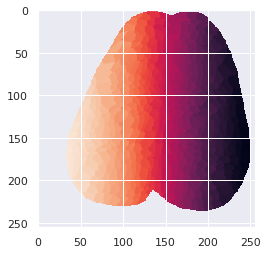

In [17]:
with h5py.File(step_0_root+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

In [18]:
def IsPointInROI(x1, y1, x2, y2, x, y) : 
    if (x > x1 and x < x2 and y > y1 and y < y2) : 
        return True
    else: 
        return False

cm241_8_runB_stim_1   1
cm241_8_runH_stim_1   1
cm241_8_runI_stim_1   20
cm241_8_runJ_stim_1   9
cm241_8_runK_stim_1   6


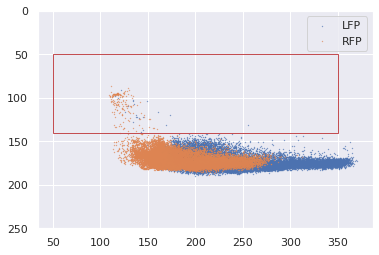

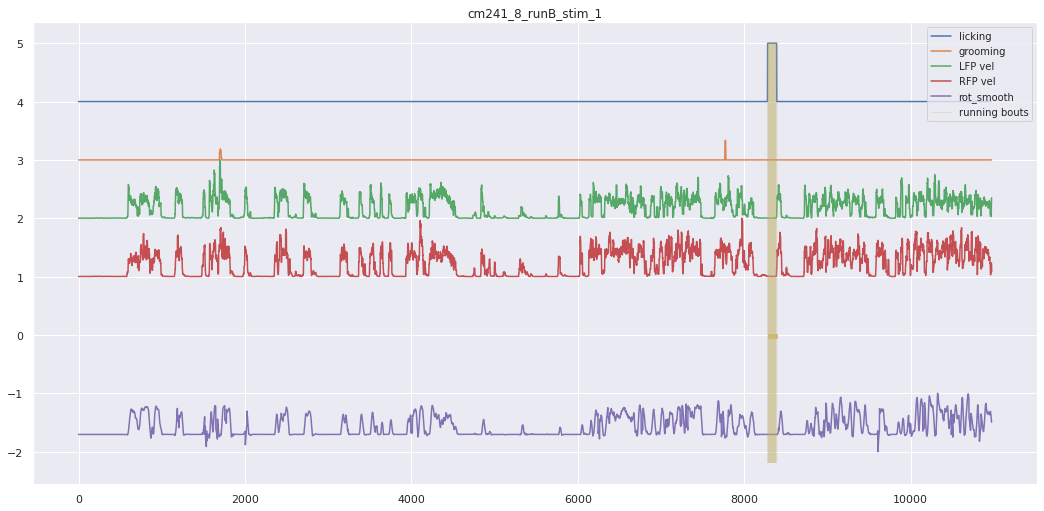

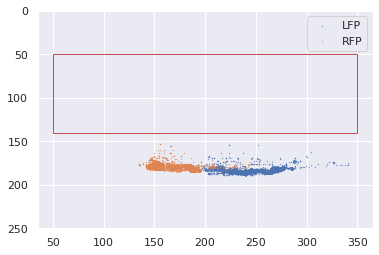

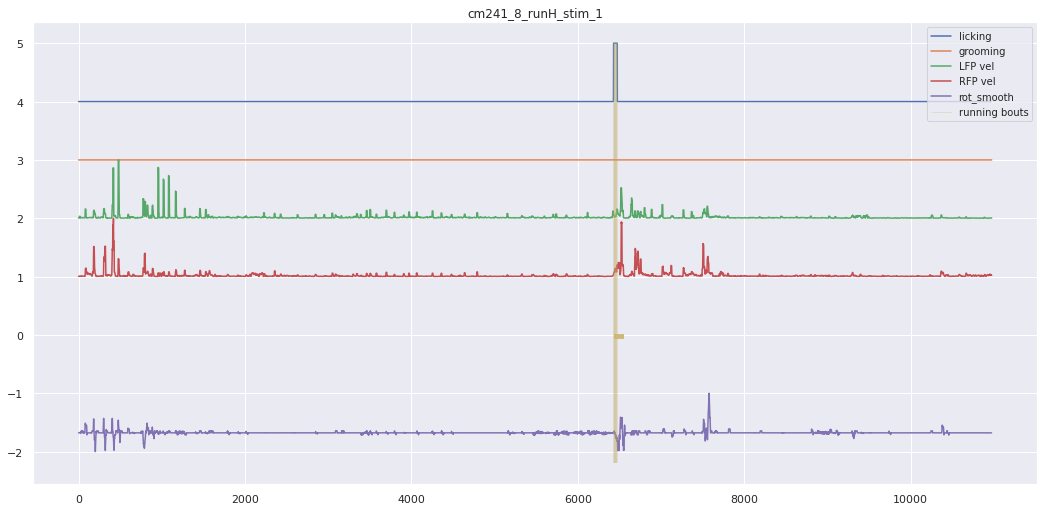

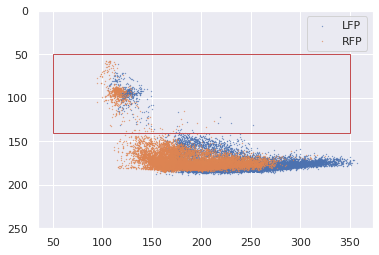

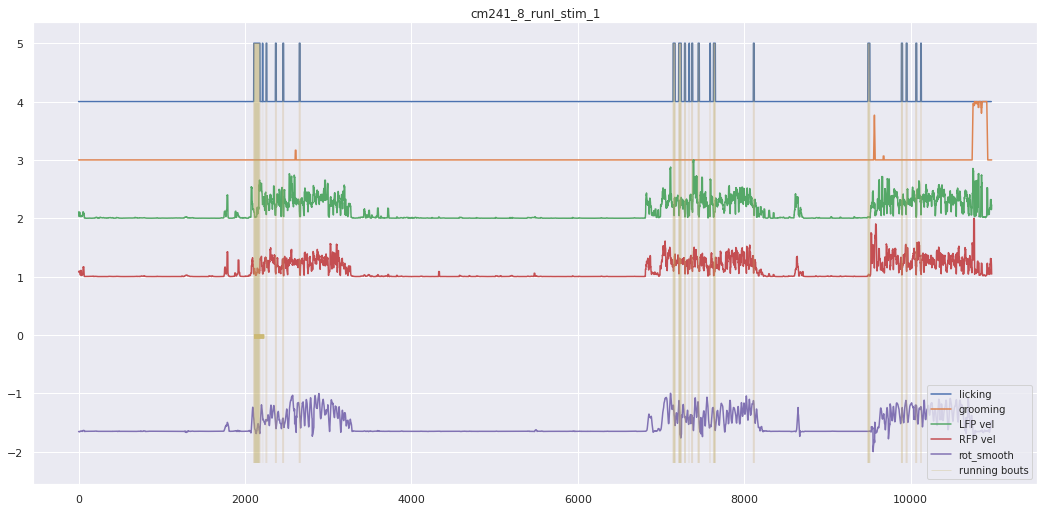

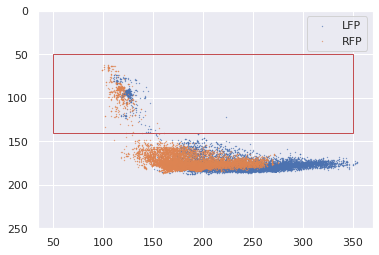

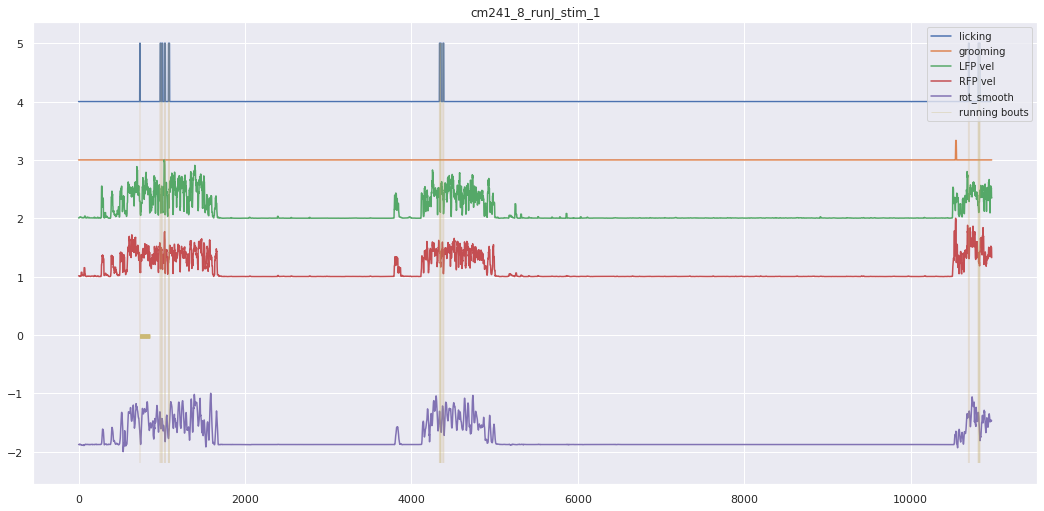

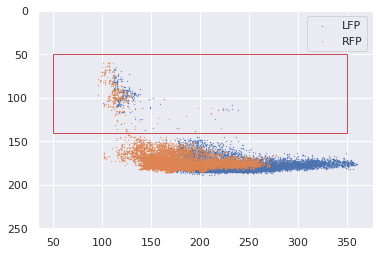

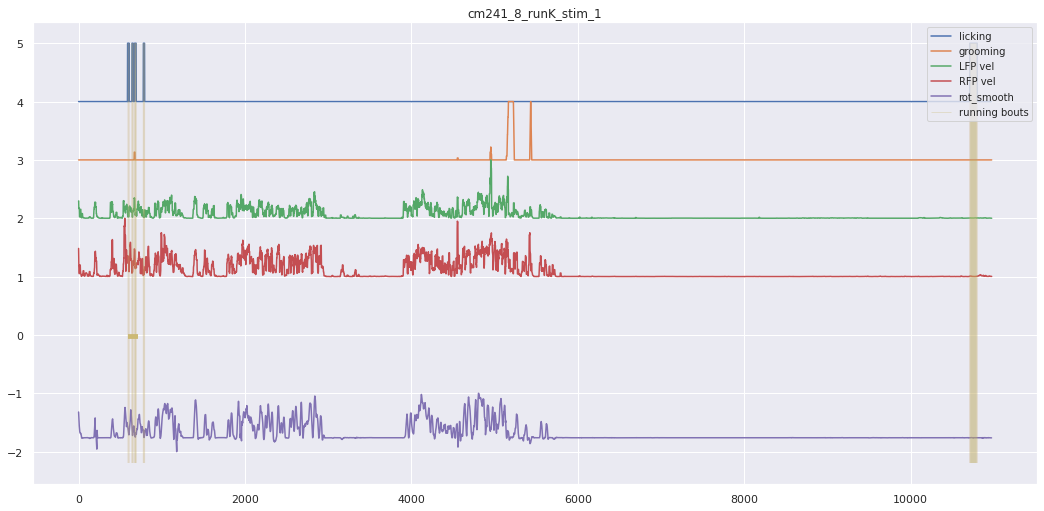

In [19]:
sns.set()
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

T_PRE = 120
T_POST = 120
T=T_PRE+T_POST
num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1)))) 

M_jrgeco = np.empty((num_regions,T,0))
M_chbt = np.empty((num_regions,T,0))

M_day_label =  np.empty((0))
M_face_pc = np.empty((T,0))
M_body_pc = np.empty((T,0))
M_LFP_vel = np.empty((T,0))
M_RFP_vel = np.empty((T,0))
M_licking = np.empty((T,0))
M_ind = np.empty((0))
M_is_groom = np.empty((T,0))
M_rotf = np.empty((T,0))

for i_file,fname in enumerate(file_list): 
    f = h5py.File(fname,'r')
    ################################### identity 
    run_name = fname[-15:-4]
    day = fname.split(mouse+'/')[1].split('/')[0]
    mouse_day = mouse+'_'+day
    run = fname[-15:-11]
    
    try:
        with h5py.File(fname,'r') as f_H: 
            H = np.array(f_H['H']).transpose() #(36,11975)       
            H = H[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
            total_tpt=H.shape[-1]
            # H_gcamp = np.array(f_H['H_gcamp']).transpose() #(36,11975)       
            # H_gcamp = H_gcamp[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
            # H_chbt = np.array(f_H['H_chbt']).transpose() #(36,11975)       
            # H_chbt = H_chbt[:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming
            m=f_H['m']
            a=np.array(m['DAQ_ds'])
            rot = np.rad2deg(np.unwrap(a[:,-1]))
            rot = np.diff(rot)
            z = np.abs(stats.zscore(rot))
            threshold = 3
            outlier_ind = np.squeeze(np.where(z > 5))
            rot[outlier_ind]=np.nan
            rot[0]=0 # in case first frame is nan
            rot_smooth = np.array(stats.zscore(np.squeeze(pd.DataFrame(rot).interpolate().rolling(20).mean().fillna(0))))
            rot_smooth = rot_smooth[500:-506]
            
    except:
        print('missing',mouse,day,'H_'+run+'_stim_1.mat')
        continue




    f_name_dlc = glob.glob(dlc_path + mouse_day+'_'+run+"*h5", recursive=True)[0] # target at specific run
    Dataframe = pd.read_hdf(f_name_dlc)
    scorer = Dataframe.keys()[0][0] #'DLC_resnet101_whiskeyOct2shuffle1_252000'
    new_df = Dataframe[scorer] # de-level

    paws_vel_df = pd.DataFrame()
    bodyparts=Dataframe.columns.get_level_values(1).drop_duplicates()

    for i_bpt,bpt in enumerate(bodyparts):
        vel = time_in_each_roi.calc_distance_between_points_in_a_vector_2d(np.vstack([new_df[bpt]['x'].values.flatten(), new_df[bpt]['y'].values.flatten()]).T)
        vel = pd.DataFrame(vel).rolling(30).std()
        vel = np.mean(vel[:-1].values.reshape((-1,3)),axis=1)
        paws_vel_df[bpt] = vel[500:-505]


    x_top_left = 50
    y_top_left = 50

    out_h = 90
    out_w = 300
    y = int(x_top_left)
    x = int(y_top_left)
    
    from matplotlib import patches
    fig,ax = plt.subplots(1)
    plt.scatter(new_df['LFP']['x'],new_df['LFP']['y'],s=0.1,label='LFP')
    plt.scatter(new_df['RFP']['x'],new_df['RFP']['y'],s=0.1,label='RFP')
    rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='r',facecolor='none')
    plt.ylim([0,250])
    plt.legend()
    ax.add_patch(rect)
    plt.gca().invert_yaxis()

    is_groom_LFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['LFP']['x'], row['LFP']['y']), axis=1)
    is_groom_RFP = new_df.apply(lambda row: IsPointInROI(x, y, x+out_w, y+out_h,row['RFP']['x'], row['RFP']['y']), axis=1)
    is_groom = np.logical_and(is_groom_LFP,is_groom_RFP)
    is_groom_smooth = is_groom.rolling(30).mean()

    is_groom_smooth_ds = np.mean(is_groom_smooth[:-1].values.reshape((-1,3)),axis=1) #(11980,)
    is_groom_smooth_ds = is_groom_smooth_ds[500:-505]

    with(h5py.File(pjoin(step_3_root,mouse,day,
                         run+'_cam_pc.mat'),'r')) as f_b:
        motionS = f_b['motionS']# this is the HDF5 reference
        motion_pc = {key: [] for key in list(motionS.keys())} 
        for key in list(motionS.keys()):
            motion_pc[key] = pd.DataFrame(motionS[key]).transpose()# this is the actual data
            motion_pc[key] = motion_pc[key].rolling(window=30,axis=1).std()
            ss=motion_pc[key].shape
            tocut = ss[1]%3
            if tocut ==0:
                motion_pc[key] = np.mean(motion_pc[key].values.reshape((ss[0],int(ss[1]/3),3)),axis=2)
            else:
                motion_pc[key] = np.mean(motion_pc[key].iloc[:,:-tocut].values.reshape((ss[0],-1,3)),axis=2)
            motion_pc[key]=motion_pc[key][:,500:-505]#^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^trimming


    face_pc = stats.zscore(motion_pc['face'][:200,:].mean(axis=0))
    body_pc = stats.zscore(motion_pc['body'][:200,:].mean(axis=0))
    LFP_vel = stats.zscore(np.array(paws_vel_df['LFP']))
    RFP_vel = stats.zscore(np.array(paws_vel_df['RFP']))
        
        

        
    ################### plotting stuffs + ***[start_stop_ind]***

    start_stop_ind=pd.DataFrame(time_dict[mouse_day+'_'+run])
    start_stop_ind=start_stop_ind/3-500
    start_stop_ind=start_stop_ind.round().astype('int')
    start_stop_ind['duration'] = start_stop_ind[1]-start_stop_ind[0]
    start_stop_ind['distance_difference'] = start_stop_ind[0] - start_stop_ind[1].shift(1)
    start_stop_ind = start_stop_ind.fillna(10000)
    start_stop_ind = start_stop_ind[start_stop_ind[0]>T_PRE]
    start_stop_ind = start_stop_ind[start_stop_ind[0]<total_tpt-T_POST]
    
    print(mouse_day+'_'+run_name,' ',len(start_stop_ind))
    
    licking =np.zeros(total_tpt);
    for i_range in range(len(start_stop_ind)):
        licking[start_stop_ind.iloc[i_range,0]:start_stop_ind.iloc[i_range,1]]=1
    
    try:
        plt.figure(figsize=(18,8.5))
        plt.plot(licking+4,label='licking')
        plt.plot(is_groom_smooth_ds+3,label='grooming')
        plt.plot(normalize(LFP_vel)+2,label='LFP vel')
        plt.plot(normalize(RFP_vel)+1,label='RFP vel')
        # plt.plot(normalize(face_pc)+0,label='face pc')
        # plt.plot(normalize(body_pc)-1,label='body pc')
        plt.plot(normalize(rot_smooth)-2,label='rot_smooth')
        for i in range(len(start_stop_ind)):
            plt.vlines(range(start_stop_ind.iloc[i,0],start_stop_ind.iloc[i,1]),
                       -2.2, 5,linewidth = 0.2,color='y',alpha=0.3)
        plt.vlines(range(start_stop_ind.iloc[0,0],start_stop_ind.iloc[0,0]+T_POST),
                       -0.05, 0.01,linewidth = 1,color='y',alpha=0.3,label='running bouts')
        plt.title(mouse_day+'_'+run_name)
        # plt.plot(H[408,:]*8-2.5,label='geco paw region')
        # plt.plot(H[338,:]*8-3.5,label='geco front region')
        plt.legend(fontsize = 10)
        
    except:
        print(mouse_day+'_'+run_name,'no start_stop_ind')
        continue

    for i in range(len(start_stop_ind)):
        M_jrgeco = np.append(M_jrgeco,H[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        # M_gcamp = np.append(M_gcamp,H_gcamp[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)
        # M_chbt = np.append(M_chbt,H_chbt[:,start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((num_regions,T,1)),axis=2)

        M_LFP_vel = np.append(M_LFP_vel,LFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_RFP_vel = np.append(M_RFP_vel,RFP_vel[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_body_pc = np.append(M_body_pc,body_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_face_pc = np.append(M_face_pc,face_pc[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_licking = np.append(M_licking,licking[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_is_groom = np.append(M_is_groom,is_groom_smooth_ds[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)
        M_rotf = np.append(M_rotf,rot_smooth[start_stop_ind.iloc[i,0]-T_PRE:start_stop_ind.iloc[i,0]+T_POST].reshape((T,1)),axis=1)

        M_day_label = np.append(M_day_label,mouse_day+'_'+run)
        M_ind = np.append(M_ind,(start_stop_ind.iloc[i,0]+500)*3)
        
        
        

In [30]:
# norm_M_jrgeco = M_jrgeco - np.mean(M_jrgeco[:,T_PRE-50:T_PRE,:],axis=1)[:,np.newaxis,:]
# norm_M_gcamp = M_gcamp - np.mean(M_gcamp[:,T_PRE-50:T_PRE,:],axis=1)[:,np.newaxis,:]
# show_map(np.mean(np.mean(norm_M_jrgeco[:,T_PRE:T_PRE+15,:],axis=1),axis=-1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)
# show_map(np.mean(np.mean(norm_M_gcamp[:,T_PRE:T_PRE+15,:],axis=1),axis=-1),caxis=[-0.03,0.03],cmap='coolwarm',IDX_sorted=IDX_sorted)

In [20]:
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model
def set_level_values(midx, level, values):
    full_levels = list(zip(*midx.values))
    names = midx.names
    if isinstance(level, str):
        if level not in names:
            raise ValueError(f'No level {level} in MultiIndex')
        level = names.index(level)
    if len(full_levels[level]) != len(values):
        raise ValueError('Values must be of the same size as original level')
    full_levels[level] = values
    return pd.MultiIndex.from_arrays(full_levels, names=names)

In [21]:
all_gathered = ['M_jrgeco','M_body_pc','M_face_pc','M_is_groom',
               'M_day_label','M_ind','M_licking','M_LFP_vel','M_RFP_vel','M_rotf']
all_gathered_dict = {key:[] for key in all_gathered}
for key in all_gathered_dict:
    exec("all_gathered_dict[key] = {}".format(key))

In [22]:
scipy.io.savemat(str(PREPARES / "epochs-licking") + "/"+mouse+'_raw.mat',
                       all_gathered_dict)

# save_model(data_joint,'/scratch/users/wx2203/new_analysis_locker/pub-locker/wheel-running/'+mouse+'_dlc_joint')